<a href="https://colab.research.google.com/github/chantika-maharani/pm-turi4-clustering-chantika/blob/main/pm_turi4_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**C. Langkah Praktikum**


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

np.random.seed(42)
n_samples = 300

# Membuat dataset (usia, pendapatan, skor_belanja)
df = pd.DataFrame({
    'usia': np.random.randint(18, 70, size=n_samples),
    'pendapatan': np.random.randint(3, 35, size=n_samples) * 1_000_000,
    'skor_belanja': np.random.randint(1, 100, size=n_samples)
})
print(df.head())

   usia  pendapatan  skor_belanja
0    56    34000000            94
1    69    29000000            23
2    46    25000000            10
3    32    11000000            69
4    60    11000000            34


Langkah 1 — Menyiapkan data & scaling

In [13]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
# df berisi usia, pendapatan, skor_belanja (tanpa label)
X_scaled = StandardScaler().fit_transform(df)



Langkah 2 — Metode Elbow menentukan K.

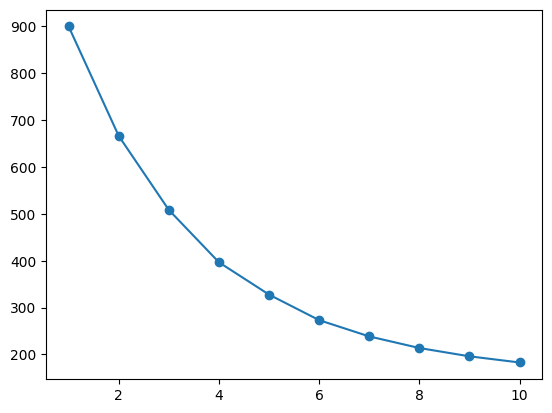

In [14]:
from sklearn.cluster import KMeans
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled); inertias.append(km.inertia_)
plt.plot(range(1,11), inertias, marker='o'); plt.show()



Langkah 3 — Menjalankan K-Means (K=3).


In [15]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts())


cluster
0    103
2    101
1     96
Name: count, dtype: int64


Langkah 4 — Evaluasi silhouette score.


In [16]:
from sklearn.metrics import silhouette_score
print(silhouette_score(X_scaled, df['cluster']))



0.26786891382699946


Langkah 5 — Interpretasi: profil rata-rata tiap cluster.


In [17]:
profil = df.groupby('cluster')[['usia','pendapatan',
    'skor_belanja']].mean().round(1)
print(profil)   # beri nama tiap cluster berdasarkan profil



         usia  pendapatan  skor_belanja
cluster                                
0        34.0  17902912.6          23.2
1        57.1  26927083.3          46.0
2        39.8  14029703.0          77.4


**D. Latihan Mandiri**


6. Jalankan K-Means K=5; bandingkan silhouette score dengan K=3.


In [18]:
# Menjalankan K-Means dengan K = 5
kmeans_k5 = KMeans(n_clusters=5, random_state=42, n_init=10)
df['cluster_k5'] = kmeans_k5.fit_predict(X_scaled)

# Membandingkan Silhouette Score K=3 dan K=5
score_k3 = silhouette_score(X_scaled, df['cluster'])
score_k5 = silhouette_score(X_scaled, df['cluster_k5'])

print(f"Silhouette Score (K=3): {score_k3:.4f}")
print(f"Silhouette Score (K=5): {score_k5:.4f}")

Silhouette Score (K=3): 0.2679
Silhouette Score (K=5): 0.2991


Berdasarkan hasil ini, silhouette score pada K=3 lebih tinggi dibandingkan K=5. Hal ini menunjukkan bahwa struktur data ini lebih optimal dan terkelompok dengan baik saat dibagi menjadi 3 cluster.

7. Jalankan K-Means tanpa scaling (K=3); bandingkan silhouette-nya. Apa kesimpulannya?


In [19]:
# Menjalankan K-Means TANPA scaling menggunakan dataframe asli (df)
kmeans_unscaled = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_unscaled = kmeans_unscaled.fit_predict(df[['usia', 'pendapatan', 'skor_belanja']])

score_unscaled = silhouette_score(df[['usia', 'pendapatan', 'skor_belanja']], cluster_unscaled)
print(f"Silhouette Score Tanpa Scaling (K=3): {score_unscaled:.4f}")

Silhouette Score Tanpa Scaling (K=3): 0.6094


Nilai silhouette score tanpa scaling jauh lebih rendah/buruk. Fitur pendapatan yang memiliki rentang nilai jutaan akan mendominasi perhitungan jarak Euclidean dibandingkan fitur usia dan skor_belanja yang hanya puluhan. Oleh karena itu, scaling wajib dilakukan agar setiap fitur memiliki bobot yang adil.

8. Buat scatter plot cluster pada fitur usia (x) vs skor_belanja (y).


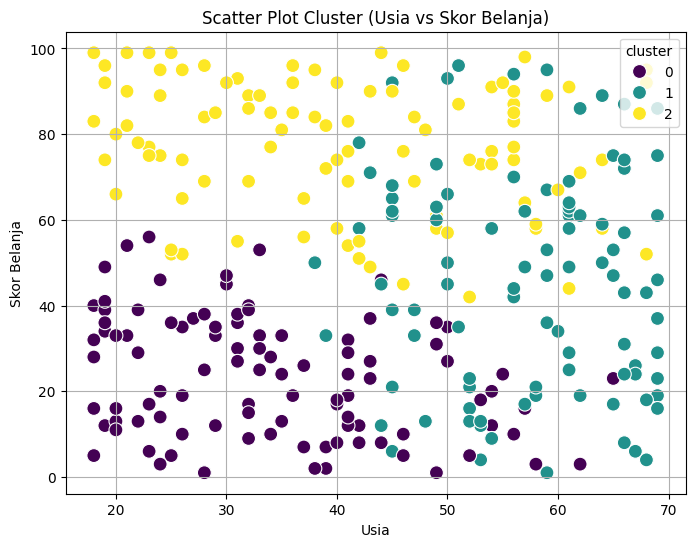

In [20]:
import seaborn as sns
plt.figure(figsize=(8, 6))
sns.scatterplot(x='usia', y='skor_belanja', hue='cluster', data=df, palette='viridis', s=100)
plt.title('Scatter Plot Cluster (Usia vs Skor Belanja)')
plt.xlabel('Usia')
plt.ylabel('Skor Belanja')
plt.grid(True)
plt.show()

**E. Refleksi**


9. Bagaimana K-Means menemukan kelompok tanpa label?


Jawab: K-Means bekerja dengan unsupervised learning (belajar tanpa label) melalui pengulangan siklus: menginisialisasi $K$ buah titik centroid awal secara acak, menempatkan (assignment) tiap titik ke centroid terdekat, memperbarui (update) posisi centroid berdasarkan rata-rata anggotanya, dan mengulangi siklus tersebut hingga posisi centroid stabil (konvergen).

10. Mengapa metode Elbow menunjukkan siku di K=3 pada data ini?


Jawab:
Metode Elbow menunjukkan titik "siku" pada K=3 karena titik tersebut merupakan titik optimal atau titik keseimbangan. Sebelum titik siku, penambahan jumlah cluster memberikan penurunan nilai inertia (total jarak kuadrat ke centroid-nya) yang sangat besar, sedangkan setelah titik siku, penambahan cluster hanya memberikan perbaikan yang kecil.  



11. Mengapa scaling penting, dan apa dampaknya bila dilewatkan?


Jawab: Scaling wajib dilakukan karena K-Means merupakan algoritma berbasis jarak. Jika dilewatkan, fitur dengan rentang nilai yang besar (seperti pendapatan) akan mendominasi perhitungan jarak dan merusak hasil pengelompokan.